# AP 155 Lab Exercise
---
## Exercise 9: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Camello, Zack Kenshin)_:
- _Student No._: 2024-08825
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** 

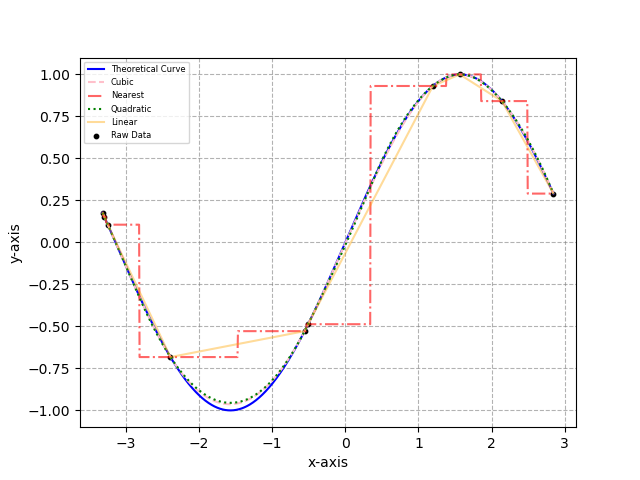

**Figure 2. Real-world data reconstruction.** 

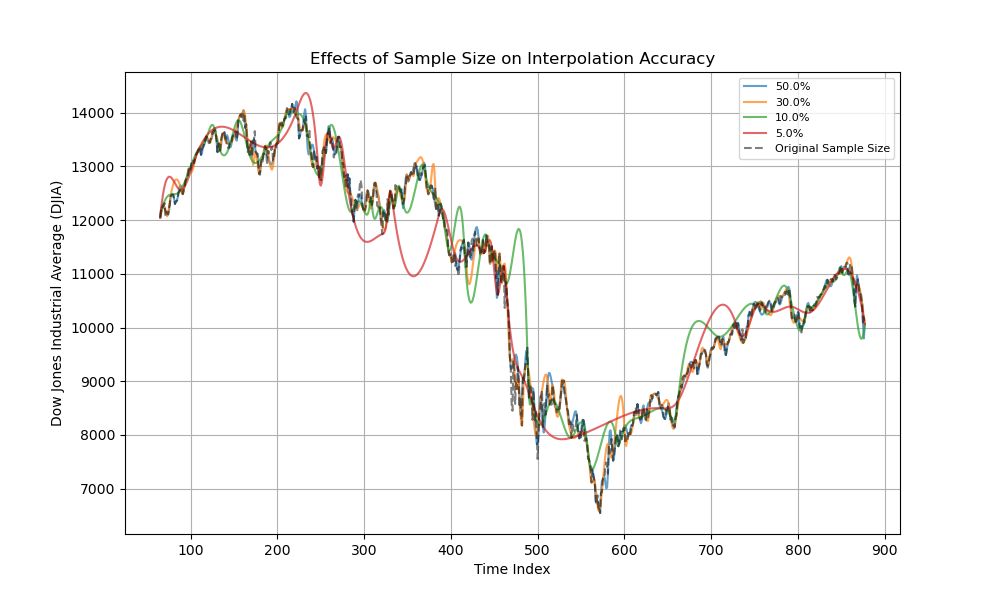

### Report discussion

**Interpolator comparison:** 

As shown in Figure 1, the capability of each method in terms of reproducing the original function varies greatly. The nearest-neighbor method especially does not capture the original function, as it instead creates a step-like pattern in connecting points, thus completely missing the curvature of the original function. On the other hand, linear interpolation improves on this by directly connecting consecutive points in a straight line. Although this method is effective with enough data points, at low data points, this method similarly misses the curvature of the original equation. In comparison, both quadratic and cubic splines are able to generate continuous curves that closely follow the original function. In particular, the cubic spline method diverges? the least between all four (4) methods.

**Sampling-level comparison:** 

As shown in Figure 2, the sampling size and reconstruction accuracy have a directly proportional relationship. Although it is not an exact match, at 50% sampling size, the algorithm is able to interpolate most of the original data's behaviors, with only minor deviations at certain intervals. At a 30% sampling size, the difference in accuracy is only slightly lower, in which there are minor spikes or overshoots. On the other hand, both 10% and 5% sampling sizes clearly miss most of the finer fluctuations in data, entirely skipping certain peaks and valleys, and instead creating large curves to bridge these gaps.

### Other comments

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [2]:
N = 1000
sample = 10
x = np.linspace(-4, 4, N)

x_sample = np.sort(rng.choice(x, sample, replace = False))
y_sample = np.sin(x_sample)
x_fine = np.linspace(x_sample[0], x_sample[-1], N)
y_fine = np.sin(x_fine)

cubic = interpolate.CubicSpline(x_sample, y_sample)
nearest = interpolate.interp1d(x_sample, y_sample, kind="nearest")
linear = interpolate.interp1d(x_sample, y_sample)
quadratic = interpolate.make_interp_spline(x_sample, y_sample, k = 2)

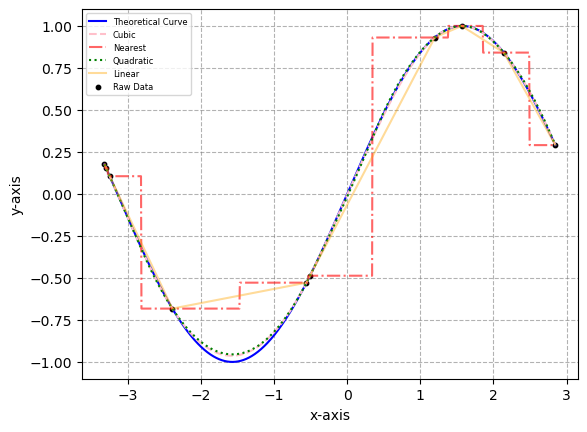

In [3]:
plt.figure()

plt.plot(x_fine, y_fine, color = "blue", label = "Theoretical Curve")
plt.plot(x_fine, cubic(x_fine), color = "pink", label = "Cubic", linestyle='--')
plt.plot(x_fine, nearest(x_fine), color = "red", label = "Nearest", alpha = 0.6, linestyle='-.')
plt.plot(x_fine, quadratic(x_fine), color = "green", label = "Quadratic", linestyle=':')
plt.plot(x_fine, linear(x_fine), color = "orange", label = "Linear", alpha = 0.4)
plt.scatter(x_sample, y_sample, color="black", label="Raw Data", s = 10)

plt.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.legend(fontsize = 6, loc = "upper left")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.savefig("Comparison of Interpolation Methods (sine)")
plt.show()

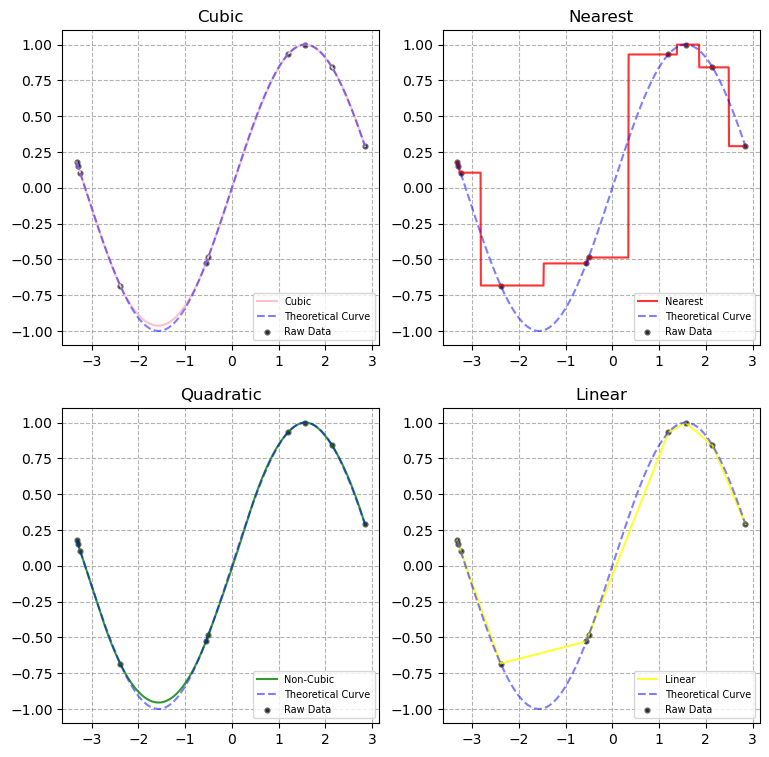

In [4]:
fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x_fine, cubic(x_fine), color = "pink", label = "Cubic")
axs[0, 0].plot(x_fine, y_fine, linestyle='--', color = "blue", alpha = 0.5, label = "Theoretical Curve")
axs[0, 0].scatter(x_sample, y_sample, color="black", linewidth=2, label="Raw Data", alpha=0.60, s = 6)
axs[0, 0].set_title("Cubic")
axs[0, 0].grid(True, linestyle='--', alpha=0.6, color='gray')
axs[0, 0].legend(fontsize = 7, loc = "lower right")

axs[0, 1].plot(x_fine, nearest(x_fine), color = "red", alpha = 0.8, label = "Nearest")
axs[0, 1].plot(x_fine, y_fine, linestyle='--', color = "blue", alpha = 0.5, label = "Theoretical Curve")
axs[0, 1].scatter(x_sample, y_sample, color="black", linewidth=2, label="Raw Data", alpha=0.60, s = 6)
axs[0, 1].set_title("Nearest")
axs[0, 1].grid(True, linestyle='--', alpha=0.6, color='gray')
axs[0, 1].legend(fontsize = 7, loc = "lower right")

axs[1, 0].plot(x_fine, quadratic(x_fine), color = "green", alpha = 0.8, label = "Non-Cubic")
axs[1, 0].plot(x_fine, y_fine, linestyle='--', color = "blue", alpha = 0.5, label = "Theoretical Curve")
axs[1, 0].scatter(x_sample, y_sample, color="black", linewidth=2, label="Raw Data", alpha=0.60, s = 6)
axs[1, 0].set_title("Quadratic")
axs[1, 0].grid(True, linestyle='--', alpha=0.6, color='gray')
axs[1, 0].legend(fontsize = 7, loc = "lower right")

axs[1, 1].plot(x_fine, linear(x_fine), color = "yellow", alpha = 0.8, label = "Linear")
axs[1, 1].plot(x_fine, y_fine, linestyle='--', color = "blue", alpha = 0.5, label = "Theoretical Curve")
axs[1, 1].scatter(x_sample, y_sample, color="black", linewidth=2, label="Raw Data", alpha=0.60, s = 6)
axs[1, 1].set_title("Linear")
axs[1, 1].grid(True, linestyle='--', alpha=0.6, color='gray')
axs[1, 1].legend(fontsize = 7, loc = "lower right")


### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%.

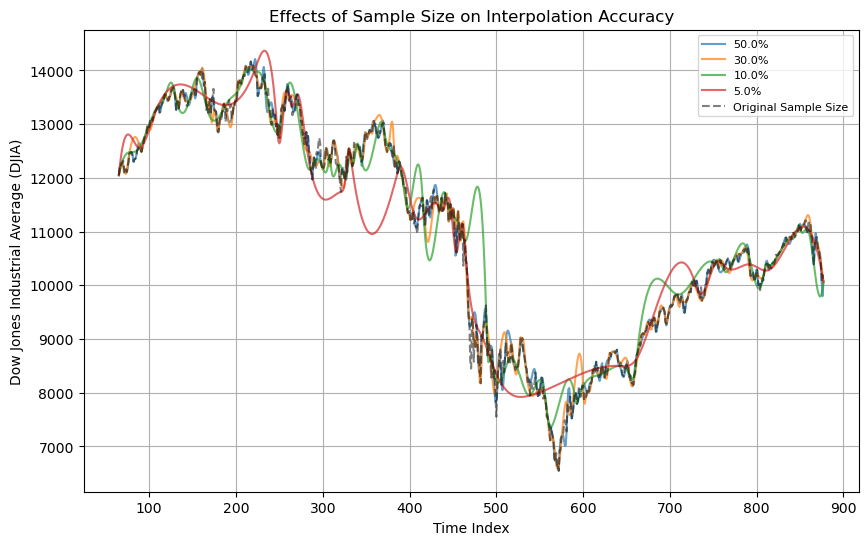

In [5]:
with open("dow.txt", "r") as file:
    data = np.array([float(line.strip()) for line in file])

data_range = np.arange(len(data))
n_total = len(data)
size = [0.5, 0.3, 0.1, 0.05]

# Ensures all graphs end and start at the same points for reference
while True:
    bound1 = rng.integers(0, n_total)
    bound2 = rng.integers(0, n_total)
    start = min(bound1, bound2)
    end = max(bound1, bound2)

    if (end - start) >= int(n_total * 0.5):
        break

# Shorten the reference data for comparison between the same bounds
shortened_range = data_range[start:end]
shortened_data = data[start:end]

plt.figure(figsize=(10, 6))

for i in size:
    sample = int(round(len(shortened_range) * i))

    # Makes a random selection within our Start and End bounds
    interior_indices = rng.choice(np.arange(1, len(shortened_range) - 1), (sample - 2), replace=False)

    # Makes our random indices by appending 0 and the last index within our shortened range into our random interior indices
    rand_indices = np.sort(np.append(interior_indices, [0, len(shortened_range) - 1]))
    data_x = shortened_range[rand_indices]
    data_y = shortened_data[rand_indices]

    cubic = interpolate.CubicSpline(data_x, data_y)

    plt.plot(shortened_range, cubic(shortened_range), alpha = 0.7, label = f"{i * 100}%")

plt.plot(shortened_range, shortened_data, color="black", linestyle="--", alpha = 0.5, label="Original Sample Size")
plt.title("Effects of Sample Size on Interpolation Accuracy")
plt.xlabel("Time Index")
plt.ylabel("Dow Jones Industrial Average (DJIA)")
plt.legend(fontsize=8, loc = "upper right")
plt.grid()
plt.savefig("Comparison of Sample Sizes")
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

In [6]:
with open("dow.txt", "r") as file:
    data = np.array([float(line.strip()) for line in file])

data_range = np.arange(len(data))
n_total = len(data)

# Ensures all graphs end and start at the same points for reference
while True:
    bound1 = rng.integers(0, n_total)
    bound2 = rng.integers(0, n_total)
    start = min(bound1, bound2)
    end = max(bound1, bound2)

    if (end - start) >= int(n_total * 0.5):
        break

# Shorten the reference data for comparison between the same bounds
shortened_range = data_range[start:end]
shortened_data = data[start:end]

sample = int(round(len(shortened_range) * 0.3))
interior_indices = rng.choice(np.arange(1, len(shortened_range) - 1), (sample - 2), replace=False)

rand_indices = np.sort(np.append(interior_indices, [0, len(shortened_range) - 1]))
data_x = shortened_range[rand_indices]
data_y = shortened_data[rand_indices]

# Same with problem 2 except computes for the different methods
cubic = interpolate.CubicSpline(data_x, data_y)
nearest = interpolate.interp1d(data_x, data_y, kind="nearest")
linear = interpolate.interp1d(data_x, data_y)
quadratic = interpolate.make_interp_spline(data_x, data_y, k = 2)

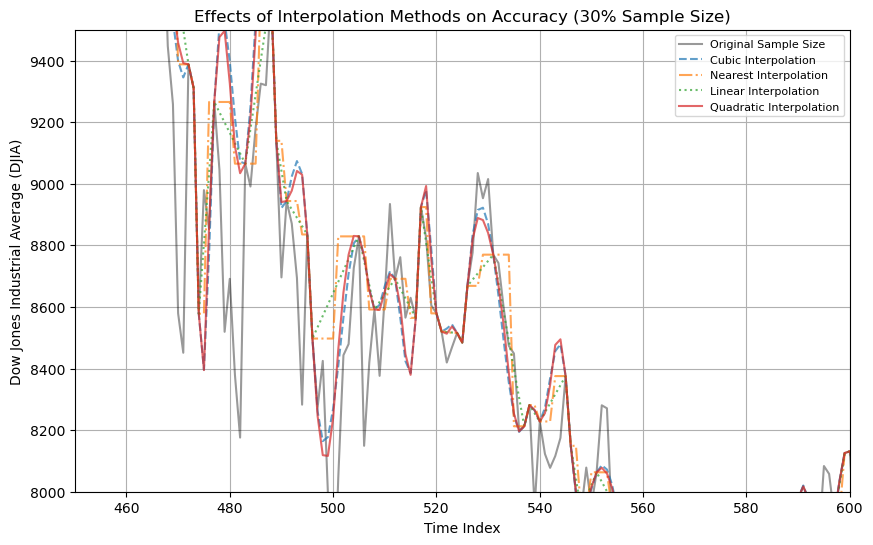

In [7]:
plt.figure(figsize=(10, 6))

plt.plot(shortened_range, shortened_data, color="black", alpha = 0.4, label="Original Sample Size")
plt.plot(shortened_range, cubic(shortened_range), alpha = 0.7, label = "Cubic Interpolation", linestyle="--")
plt.plot(shortened_range, nearest(shortened_range), alpha = 0.7, label = "Nearest Interpolation", linestyle="-.")
plt.plot(shortened_range, linear(shortened_range), alpha = 0.7, label = "Linear Interpolation", linestyle=":")
plt.plot(shortened_range, quadratic(shortened_range), alpha = 0.7, label = "Quadratic Interpolation")

plt.title("Effects of Interpolation Methods on Accuracy (30% Sample Size)")
plt.legend(fontsize=8, loc = "upper right")
plt.xlabel("Time Index")
plt.ylabel("Dow Jones Industrial Average (DJIA)")
plt.ylim(8000,9500)
plt.xlim(450,600)
plt.grid()
plt.savefig("Comparison of Interpolation Methods (30% Sample Size)")
plt.show()

### Problem  code summary

For Problem 1, the code above simply takes 10 elements out of the original input functions (x values), alongside their corresponding outputs (y values), and utilizes nearest-neightbor, linear, quadratic, and cubic interpolation to attempt to reconstruct the original curve. For Problem 2 and 3, however, this is expanded upon to use real-world data instead of synthetic outputs in which the same previous process is done, but instead have varying sampling sizes.

---